# Bangla Handwritten Word Recognition: Model Training
### Assignment 04 · Skills for Industry Competitiveness and Innovation Program (SICIP), BRAC University

| | |
|---|---|
| **Name** | Khandakar Humyra Oyshi |
| **Student ID** | 1000128211 |
| **Dataset** | [BanglaLekha-Isolated](https://data.mendeley.com/datasets/hf6sf8zrkc/2) (Mendeley Data) |
| **Hardware** | Google Colab, NVIDIA Tesla T4 GPU |

This notebook trains the whole-word recognition model used by the Streamlit app (`app.py`).
All training logic lives in `train.py`; the notebook runs it on a GPU and records two experiments in **MLflow**.

**Approach in brief.** BanglaLekha-Isolated contains isolated characters only, with no word images and no vowel
signs (কার). `train.py` therefore builds word images on the fly: real handwritten character images are joined
with a matra and vowel signs drawn as pen strokes, and the same vocabulary is also rendered with Bangla fonts and
distorted to look handwritten. A CNN + BiLSTM network trained with CTC loss reads the whole word image and
outputs its character sequence, which is then matched to the vocabulary in `words.txt`.

## 1. Environment

In [1]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-df3b5ebe-d14e-4076-50fb-84d43668bd7d)


### 1.1 Project code

In [2]:
import os, zipfile
from google.colab import files

%cd /content
up = files.upload()  # bangla-ocr-assignment.zip (source code)
zipfile.ZipFile(next(iter(up))).extractall('/content')
%cd /content/bangla-ocr-assignment
!ls

/content


Saving bangla-ocr-assignment.zip to bangla-ocr-assignment.zip
/content/bangla-ocr-assignment
app.py		   github_link.txt	   README.md	     words.txt
artifacts	   make_submission_zip.py  requirements.txt
colab_train.ipynb  models		   screenshots
Dockerfile	   ocr_utils.py		   train.py


### 1.2 Dependencies
Colab already provides TensorFlow with GPU support, so only MLflow is installed.

In [3]:
!pip install -q mlflow==3.18.0
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset
BanglaLekha-Isolated is downloaded directly from Mendeley Data through its public API and unzipped.
Each class is stored in a numbered folder (`Images/1` … `Images/84`).

In [4]:
import requests, glob

DATA = '/content/data'
os.makedirs(DATA, exist_ok=True)

def extract_all(folder):
    """Unzip every archive in the folder, including archives inside archives."""
    done = set()
    while True:
        zips = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not zips:
            break
        for z in zips:
            print('unzipping', z)
            zipfile.ZipFile(z).extractall(os.path.dirname(z))
            done.add(z)

api = 'https://data.mendeley.com/public-api/datasets/hf6sf8zrkc/files?folder_id=root&version=2'
for f in requests.get(api, timeout=60).json():
    name = f.get('filename')
    url = (f.get('content_details') or {}).get('download_url')
    print(name, url)
    if url:
        !wget -q --show-progress -O "$DATA/$name" "$url"

extract_all(DATA)
!find $DATA -maxdepth 4 -type d | head -20

BanglaLekha-Isolated.zip https://data.mendeley.com/public-files/datasets/hf6sf8zrkc/files/ffe73a3a-5999-4ad2-970f-3e14c141cdb1/file_downloaded
/content/data/Bangl 100%[===================>] 187.96M  18.0MB/s    in 12s     
unzipping /content/data/BanglaLekha-Isolated.zip
/content/data
/content/data/BanglaLekha-Isolated
/content/data/BanglaLekha-Isolated/Images
/content/data/BanglaLekha-Isolated/Images/63
/content/data/BanglaLekha-Isolated/Images/38
/content/data/BanglaLekha-Isolated/Images/59
/content/data/BanglaLekha-Isolated/Images/37
/content/data/BanglaLekha-Isolated/Images/4
/content/data/BanglaLekha-Isolated/Images/54
/content/data/BanglaLekha-Isolated/Images/31
/content/data/BanglaLekha-Isolated/Images/61
/content/data/BanglaLekha-Isolated/Images/73
/content/data/BanglaLekha-Isolated/Images/56
/content/data/BanglaLekha-Isolated/Images/11
/content/data/BanglaLekha-Isolated/Images/58
/content/data/BanglaLekha-Isolated/Images/17
/content/data/BanglaLekha-Isolated/Images/78
/content

### 2.1 Checking the folder → character mapping
Only folders 1–60 are used: the 50 basic characters (11 vowels, 39 consonants and signs) and the 10 numerals.
The grid below shows the Unicode character assigned to each folder (left) next to handwritten samples from that
folder. Every row matches, so the labels used for training are correct.

Loaded characters from /content/data/BanglaLekha-Isolated/Images: 1560 train / 240 val images
Saved /content/bangla-ocr-assignment/artifacts/class_preview.png. The printed character on the left of each row must match the handwriting.


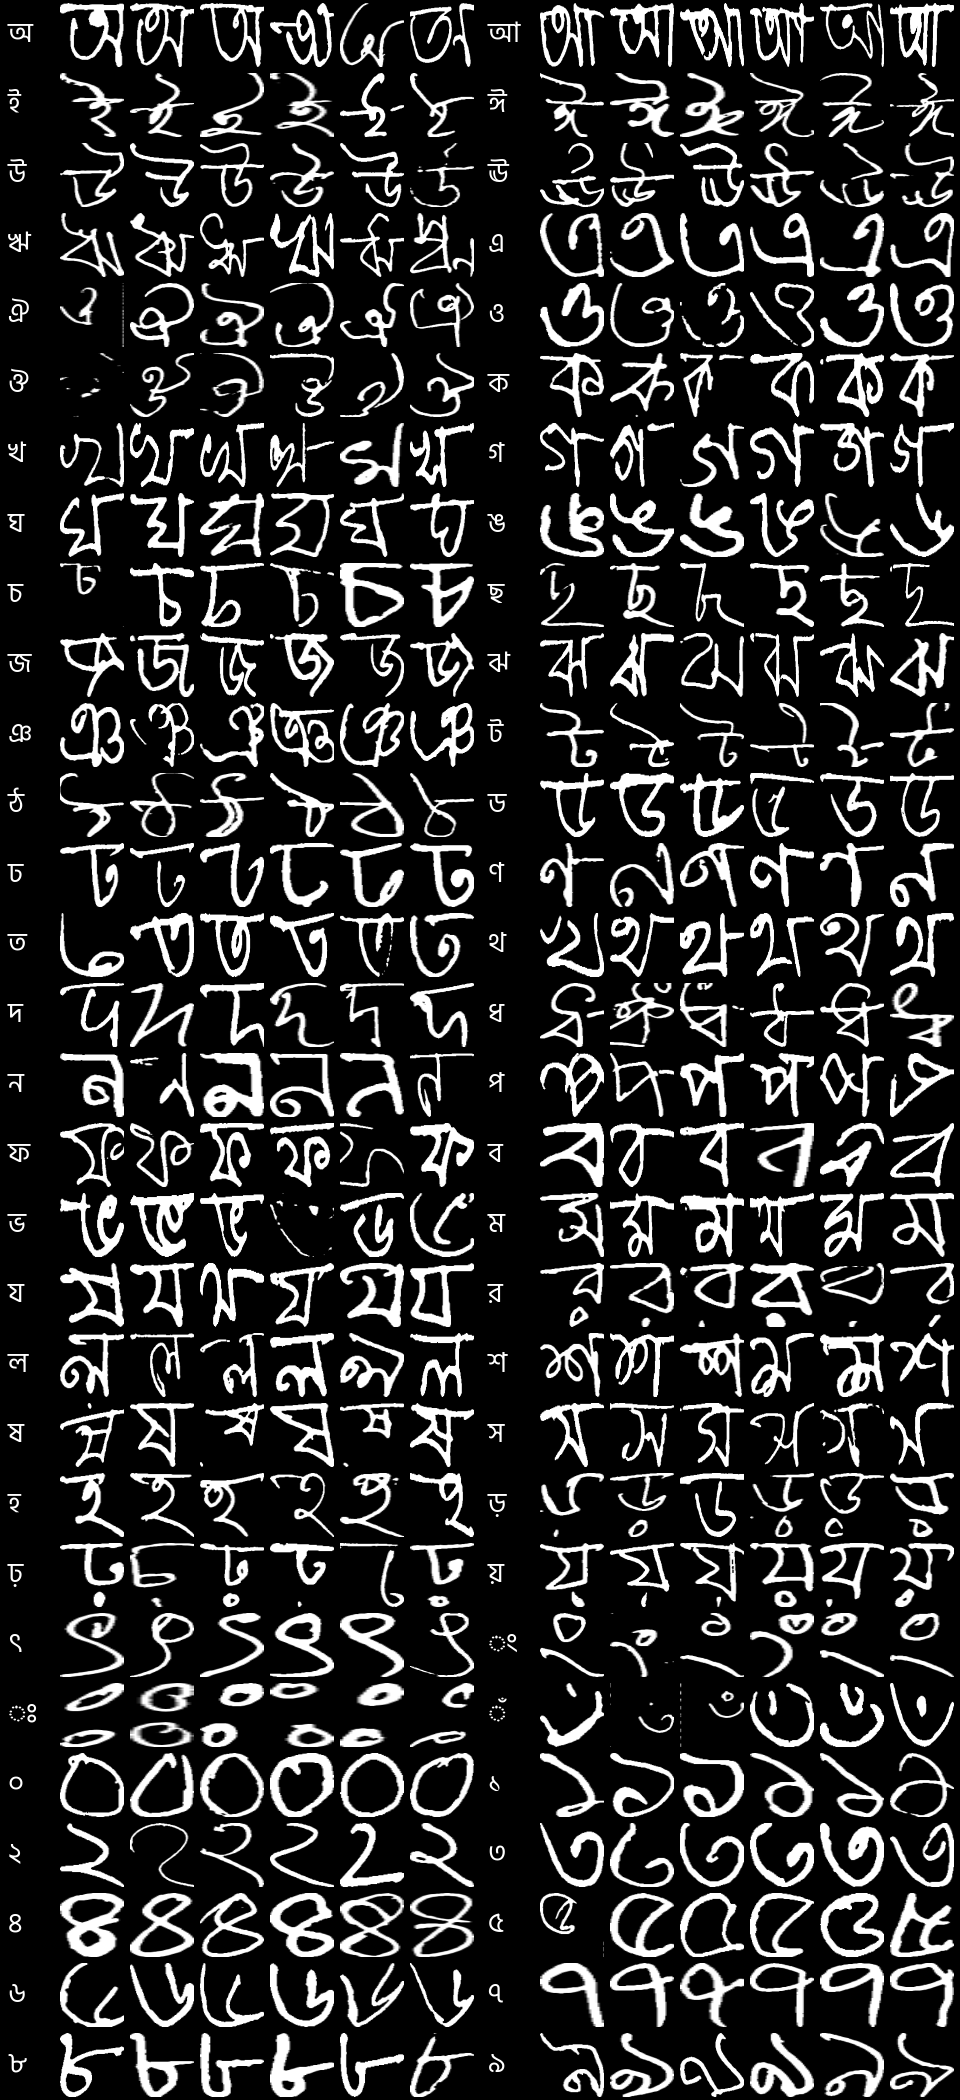

In [5]:
!python train.py --data-dir /content/data --preview-classes
from IPython.display import Image, display
display(Image('artifacts/class_preview.png'))

## 3. Training runs tracked in MLflow
Each run trains a CRNN (8 convolution layers → 2 × BiLSTM → CTC) on synthetic word images (64 × 256 pixels):
400 steps per epoch × 64 words. After every epoch the model is evaluated on 1,500 validation words built from
the held-out 15% of BanglaLekha handwriting (writers' images the model never sees in training).

Metrics logged per epoch:
- **CER**: character error rate of the raw CTC output
- **word_acc (greedy)**: share of words whose raw character sequence is exactly right
- **word_acc (lexicon)**: share of words predicted correctly after matching to the vocabulary, which is what the app shows

The checkpoint with the best vocabulary accuracy is kept, and the better of the two runs is saved to
`models/model.keras`.

### Run 1: baseline (BiLSTM 128 units, learning rate 1e-3, 8 epochs)

In [6]:
!python train.py --data-dir /content/data --run-name baseline-lstm128 --epochs 8

Loaded characters from /content/data/BanglaLekha-Isolated/Images: 51000 train / 9000 val images
Epoch 1/8
  epoch 1: CER=0.902 word_acc(greedy)=0.000 word_acc(lexicon)=0.003
400/400 - 463s - 1s/step - loss: 14.0134 - val_loss: 16.3070 - learning_rate: 0.0010
Epoch 2/8
  epoch 2: CER=0.605 word_acc(greedy)=0.075 word_acc(lexicon)=0.258
400/400 - 423s - 1s/step - loss: 8.8623 - val_loss: 8.3416 - learning_rate: 0.0010
Epoch 3/8
  epoch 3: CER=0.296 word_acc(greedy)=0.378 word_acc(lexicon)=0.740
400/400 - 422s - 1s/step - loss: 5.3103 - val_loss: 4.0540 - learning_rate: 0.0010
Epoch 4/8
  epoch 4: CER=0.166 word_acc(greedy)=0.592 word_acc(lexicon)=0.860
400/400 - 418s - 1s/step - loss: 2.7378 - val_loss: 2.2972 - learning_rate: 0.0010
Epoch 5/8
  epoch 5: CER=0.081 word_acc(greedy)=0.750 word_acc(lexicon)=0.953
400/400 - 418s - 1s/step - loss: 1.5788 - val_loss: 1.2119 - learning_rate: 0.0010
Epoch 6/8
  epoch 6: CER=0.051 word_acc(greedy)=0.855 word_acc(lexicon)=0.965
400/400 - 430s - 1s

### Run 2: larger recurrent layers, lower learning rate (BiLSTM 192 units, learning rate 5e-4, 10 epochs)

In [7]:
!python train.py --data-dir /content/data --run-name lstm192-lr5e-4 --rnn-units 192 --lr 5e-4 --epochs 10

Loaded characters from /content/data/BanglaLekha-Isolated/Images: 51000 train / 9000 val images
Epoch 1/10
  epoch 1: CER=0.850 word_acc(greedy)=0.002 word_acc(lexicon)=0.013
400/400 - 449s - 1s/step - loss: 13.6115 - val_loss: 15.1494 - learning_rate: 5.0000e-04
Epoch 2/10
  epoch 2: CER=0.536 word_acc(greedy)=0.121 word_acc(lexicon)=0.352
400/400 - 416s - 1s/step - loss: 7.5460 - val_loss: 7.9206 - learning_rate: 5.0000e-04
Epoch 3/10
  epoch 3: CER=0.179 word_acc(greedy)=0.565 word_acc(lexicon)=0.905
400/400 - 415s - 1s/step - loss: 3.5542 - val_loss: 2.4968 - learning_rate: 5.0000e-04
Epoch 4/10
  epoch 4: CER=0.096 word_acc(greedy)=0.735 word_acc(lexicon)=0.940
400/400 - 422s - 1s/step - loss: 1.7019 - val_loss: 1.4071 - learning_rate: 5.0000e-04
Epoch 5/10
  epoch 5: CER=0.043 word_acc(greedy)=0.865 word_acc(lexicon)=0.975
400/400 - 423s - 1s/step - loss: 0.9945 - val_loss: 0.6569 - learning_rate: 5.0000e-04
Epoch 6/10
  epoch 6: CER=0.062 word_acc(greedy)=0.831 word_acc(lexicon)

### Selected model

In [8]:
!cat models/best_run.json

{
  "run_id": "02b573431b91490cba5d5940f39f855d",
  "run_name": "lstm192-lr5e-4",
  "best_val_cer": 0.012991284328235488,
  "best_val_word_acc_greedy": 0.9613333333333334,
  "best_val_word_acc_lexicon": 0.9850746268656716,
  "train_minutes": 70.54400618871053
}

## 4. Results

| Run | BiLSTM units | Learning rate | Epochs | Val CER ↓ | Word acc. (greedy) | Word acc. (vocabulary) | Training time |
|---|---|---|---|---|---|---|---|
| `baseline-lstm128` | 128 | 1e-3 | 8 | 5.1% | 85.5% | 94.8% | 57 min |
| `lstm192-lr5e-4` | 192 | 5e-4 | 10 | **1.3%** | **96.1%** | **98.5%** | 71 min |

**Run 2 is the selected model** (`models/model.keras`).

**Observations**
- Both runs learn quickly: vocabulary accuracy passes 70% by epoch 3, once the network has learnt to align
  characters with image columns under CTC.
- Run 2 is better on every metric. The larger BiLSTM gives more capacity to model the context between
  neighbouring characters and vowel signs, and with the lower learning rate it kept improving up to the last epoch
  (final validation loss 0.23 vs 0.55).
- Matching to the vocabulary adds 2–9 percentage points over the raw output, because small slips such as ু vs ূ
  are corrected to the nearest known word.
- Validation words are synthetic, like the training words, so accuracy on words drawn in the app is expected to be
  lower. See *Limitations* in the README.

## 5. Export
The trained model, `labels.json` and the MLflow tracking data are packed into one archive, which is then used for
the Streamlit app and the Docker image.

In [9]:
!rm -f trained_outputs.zip && zip -qr trained_outputs.zip models labels.json artifacts/mlflow && ls -lh trained_outputs.zip
from google.colab import files
files.download('trained_outputs.zip')

-rw-r--r-- 1 root root 100M Nov 15 18:48 trained_outputs.zip
